# CS-5530 — Assignment 2 - Liberty Gladden
**Questions 1 and 2 | Colab notebook**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Colab: upload both CSV files. Local Jupyter: place them beside this notebook.
if not (Path("train.csv").exists() and Path("diabetes.csv").exists()):
    from google.colab import files
    files.upload()

cars = pd.read_csv("train.csv")
diabetes = pd.read_csv("diabetes.csv")
print("Cars:", cars.shape, "Diabetes:", diabetes.shape)

Cars: (5847, 14) Diabetes: (768, 9)


## Question 1 — Used cars (20 points)
### 1(a) Missing values and justification (4 points)
Count missing values in **every** column before cleaning. Drop `New_Price` because it is missing in most listings; filling thousands of prices would invent misleading values. Fill a small number of missing numeric values using the median, which is less affected by outliers. Preserve rows and target `Price`.

In [2]:
print("Missing values before cleaning:")
print(cars.isna().sum().to_string())

# Drop the overwhelmingly incomplete column, plus the exported index.
cars = cars.drop(columns=["New_Price", "Unnamed: 0"], errors="ignore")

Missing values before cleaning:
Unnamed: 0              0
Name                    0
Location                0
Year                    0
Kilometers_Driven       0
Fuel_Type               0
Transmission            0
Owner_Type              0
Mileage                 2
Engine                 36
Power                  36
Seats                  38
New_Price            5032
Price                   0


### 1(b) Remove units (4 points)
Convert mileage (kmpl or km/kg), engine (CC), and power (bhp) into numeric values. `New_Price` is excluded for the missing-data reason above; if retained, its `Lakh`/`Cr` values would need consistent conversion (1 Cr = 100 Lakh). Mileage units are stripped as requested, but km/kg and kmpl are not physically equivalent; interpret the combined numerical mileage column cautiously.

In [3]:
for column in ["Mileage", "Engine", "Power"]:
    cars[column] = pd.to_numeric(
        cars[column].astype(str).str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce"
    )

for column in ["Mileage", "Engine", "Power", "Seats"]:
    cars[column] = cars[column].fillna(cars[column].median())

print("Missing values after cleaning:")
print(cars.isna().sum().to_string())
print(cars[["Mileage", "Engine", "Power", "Seats"]].head())

Missing values after cleaning:
Name                 0
Location             0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
Price                0
   Mileage  Engine   Power  Seats
0    19.67  1582.0  126.20    5.0
1    13.00  1199.0   88.70    5.0
2    20.77  1248.0   88.76    7.0
3    15.20  1968.0  140.80    5.0
4    23.08  1461.0   63.10    5.0


### 1(c) One-hot encoding (4 points)
Use `pd.get_dummies` for both required categorical columns. Each category becomes its own 0/1 indicator.

In [4]:
cars = pd.get_dummies(cars, columns=["Fuel_Type", "Transmission"], dtype=int)
print(cars.filter(regex="^(Fuel_Type|Transmission)_").head())

   Fuel_Type_Diesel  Fuel_Type_Electric  Fuel_Type_Petrol  \
0                 1                   0                 0   
1                 0                   0                 1   
2                 1                   0                 0   
3                 1                   0                 0   
4                 1                   0                 0   

   Transmission_Automatic  Transmission_Manual  
0                       0                    1  
1                       0                    1  
2                       0                    1  
3                       1                    0  
4                       0                    1  


### 1(d) Create a feature (4 points)
Compute vehicle age using **2026**, the year of this assignment. The fixed year keeps results reproducible.

In [5]:
cars["Car_Age"] = 2026 - cars["Year"]
print(cars[["Year", "Car_Age"]].head())

   Year  Car_Age
0  2015       11
1  2011       15
2  2012       14
3  2013       13
4  2013       13


### 1(e) Select, filter, rename, mutate, arrange, summarize with group by (4 points)
Python Pandas equivalents: selecting columns, filtering rows, renaming, adding a calculated column, sorting, and grouping with aggregation.

In [6]:
selected = cars[["Name", "Location", "Price", "Car_Age"]]  # select
filtered = selected[selected["Price"] > 10]             # filter: cars over 10 lakhs
renamed = filtered.rename(columns={"Price": "Price_Lakhs"})  # rename
mutated = renamed.assign(Price_Rupees=renamed["Price_Lakhs"] * 100000)  # mutate
arranged = mutated.sort_values("Price_Lakhs", ascending=False)  # arrange
summary = (cars.groupby("Location")["Price"]             # group by + summarize
           .agg(Count="count", Mean_Price_Lakhs="mean")
           .sort_values("Mean_Price_Lakhs", ascending=False))
print("Selected / filtered / renamed / mutated / arranged:")
print(arranged.head().to_string(index=False))
print("\nGroup summary:")
print(summary.round(2).to_string())
print("\nCleaned data shape:", cars.shape)

Selected / filtered / renamed / mutated / arranged:
                                       Name   Location  Price_Lakhs  Car_Age  Price_Rupees
Land Rover Range Rover 3.0 Diesel LWB Vogue  Hyderabad       160.00        9    16000000.0
                 Lamborghini Gallardo Coupe      Delhi       120.00       15    12000000.0
                     Jaguar F Type 5.0 V8 S  Hyderabad       100.00       11    10000000.0
            Land Rover Range Rover Sport SE      Kochi        97.07        7     9707000.0
                         BMW 7 Series 740Li Coimbatore        93.67        8     9367000.0

Group summary:
            Count  Mean_Price_Lakhs
Location                           
Coimbatore    631             15.16
Bangalore     352             13.48
Kochi         640             11.31
Hyderabad     710             10.00
Delhi         540              9.88
Mumbai        762              9.59
Ahmedabad     218              8.57
Chennai       476              7.96
Pune          590         

**Q1 findings:** The original file contains 5,032 missing `New_Price` values out of 5,847 rows, so dropping that column avoids extensive artificial imputation. The remaining small gaps are filled with medians. The transformed data includes numerical engine, power, mileage, age, and one-hot indicators. Grouped prices describe listings by city, not causal city effects.

## Question 2 — Diabetes population (30 points)
Lecture 9 treats a known full dataset as a *population* for demonstrating sampling. Here all 768 records are the assignment-defined population. We use seed 101, as in the lecture sampling example.

In [7]:
assert len(diabetes) == 768, "Expected 768 population records"
SEED = 101
print(diabetes.shape)
print(diabetes.head())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


### 2(a) Sample 25; Glucose mean and maximum (5 points)
A random sample **without replacement** is compared against all 768 population records. The chart uses a zero baseline to avoid exaggerating differences.

                 Population  Sample (n=25)
Mean Glucose         120.89         124.48
Maximum Glucose      199.00         187.00


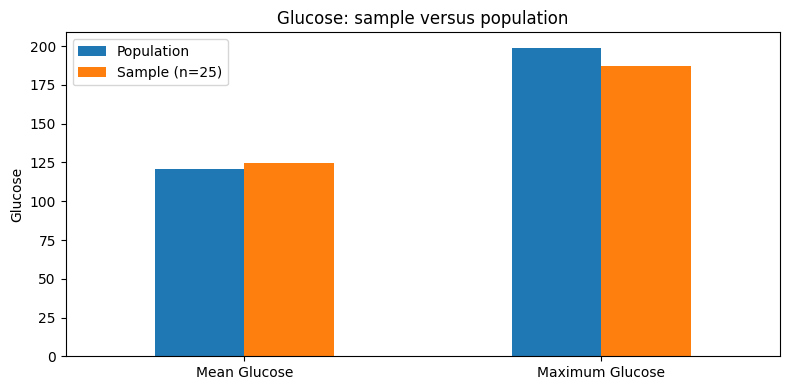

Finding: Sample mean differs from population by 3.59
Finding: Sample maximum differs by -12.0


In [8]:
sample25 = diabetes.sample(n=25, replace=False, random_state=SEED)
glucose = pd.DataFrame({
    "Population": [diabetes["Glucose"].mean(), diabetes["Glucose"].max()],
    "Sample (n=25)": [sample25["Glucose"].mean(), sample25["Glucose"].max()]
}, index=["Mean Glucose", "Maximum Glucose"])
print(glucose.round(2))
ax = glucose.plot.bar(figsize=(8, 4), rot=0, title="Glucose: sample versus population")
ax.set_ylabel("Glucose")
ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()
print("Finding: Sample mean differs from population by", round(glucose.loc["Mean Glucose", "Sample (n=25)"] - glucose.loc["Mean Glucose", "Population"], 2))
print("Finding: Sample maximum differs by", round(glucose.loc["Maximum Glucose", "Sample (n=25)"] - glucose.loc["Maximum Glucose", "Population"], 2))

### 2(b) 98th percentile of BMI (5 points)
Use Pandas `.quantile(.98)` for both sample and population, matching the lecture discussion of extreme percentiles. A small sample may estimate a tail percentile poorly.

98th percentile BMI:
 Population       47.53
Sample (n=25)    53.02
dtype: float64


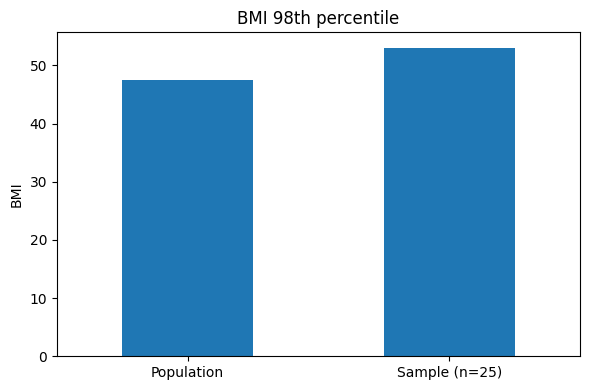

Sample minus population: 5.49


In [9]:
bmi98 = pd.Series({"Population": diabetes["BMI"].quantile(.98),
                   "Sample (n=25)": sample25["BMI"].quantile(.98)})
print("98th percentile BMI:\n", bmi98.round(2))
ax = bmi98.plot.bar(figsize=(6, 4), rot=0, title="BMI 98th percentile")
ax.set_ylabel("BMI")
ax.set_ylim(bottom=0)
plt.tight_layout(); plt.show()
print("Sample minus population:", round(bmi98["Sample (n=25)"] - bmi98["Population"], 2))

### 2(c) Bootstrap: 500 samples of 150 with replacement (10 points)
Lecture 9 explains that bootstrap resampling uses `replace=True`, so records may appear multiple times. For **each** of the 500 resamples, calculate BloodPressure mean, standard deviation, and **98th percentile** (the percentile used in 2b). Then average each statistic over the 500 trials and compare with population values. Standard deviations use Pandas `ddof=1` for each resample and population for consistent calculation. Histograms show sampling variation; vertical lines show population values.

In [10]:
boot_results = []
for i in range(500):
    boot = diabetes["BloodPressure"].sample(n=150, replace=True, random_state=SEED + i)
    boot_results.append({"Mean": boot.mean(),
                         "Std Dev": boot.std(),
                         "98th Percentile": boot.quantile(.98)})
boot_stats = pd.DataFrame(boot_results)
pop_stats = pd.Series({"Mean": diabetes["BloodPressure"].mean(),
                       "Std Dev": diabetes["BloodPressure"].std(),
                       "98th Percentile": diabetes["BloodPressure"].quantile(.98)})
comparison = pd.DataFrame({"Population": pop_stats,
                           "Average of 500 bootstraps": boot_stats.mean()})
comparison["Difference"] = comparison["Average of 500 bootstraps"] - comparison["Population"]
print("Number of resamples:", len(boot_stats), "| Size of each resample: 150 | Replacement: True")
print(comparison.round(2).to_string())

Number of resamples: 500 | Size of each resample: 150 | Replacement: True
                 Population  Average of 500 bootstraps  Difference
Mean                  69.11                      69.21        0.11
Std Dev               19.36                      19.12       -0.23
98th Percentile       99.32                      98.08       -1.24


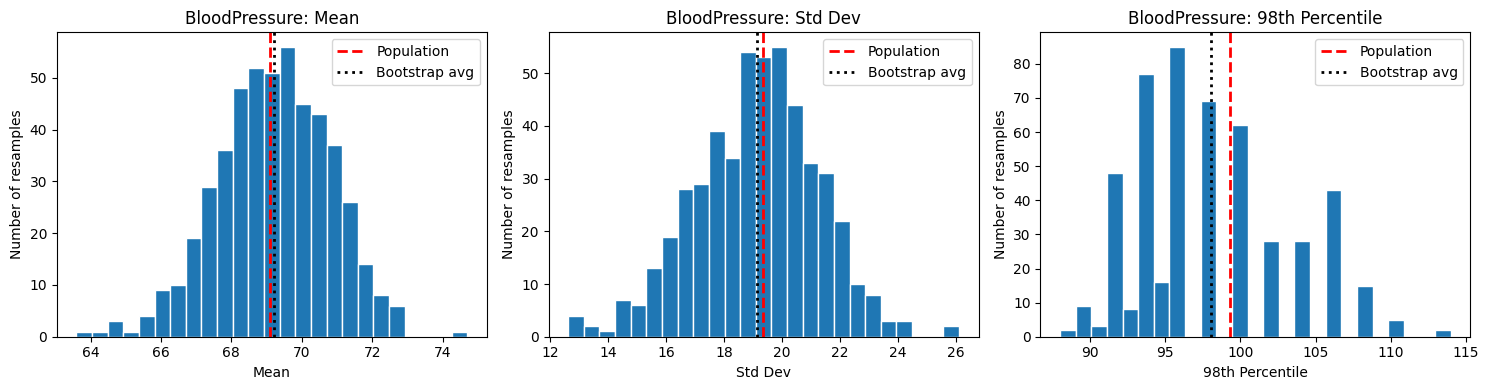

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, boot_stats.columns):
    ax.hist(boot_stats[column], bins=25, edgecolor="white")
    ax.axvline(pop_stats[column], color="red", linestyle="--", linewidth=2, label="Population")
    ax.axvline(boot_stats[column].mean(), color="black", linestyle=":", linewidth=2, label="Bootstrap avg")
    ax.set_title("BloodPressure: " + column)
    ax.set_xlabel(column)
    ax.set_ylabel("Number of resamples")
    ax.legend()
plt.tight_layout(); plt.show()

In [12]:
print("FINDINGS — BloodPressure")
for stat in comparison.index:
    p = comparison.loc[stat, "Population"]
    avg = comparison.loc[stat, "Average of 500 bootstraps"]
    diff = avg - p
    print(f"{stat}: population={p:.2f}, average bootstrap={avg:.2f}, difference={diff:+.2f}.")
print("Interpretation: The bootstrap distributions show how the statistics vary across repeated samples.")
print("The mean generally varies less than an extreme percentile; a percentile depends on relatively few tail observations.")
print("Because these resamples are drawn from the full assignment-defined population, this is a sampling demonstration,")
print("not a bootstrap from one independently collected sample as would usually happen in practice.")

FINDINGS — BloodPressure
Mean: population=69.11, average bootstrap=69.21, difference=+0.11.
Std Dev: population=19.36, average bootstrap=19.12, difference=-0.23.
98th Percentile: population=99.32, average bootstrap=98.08, difference=-1.24.
Interpretation: The bootstrap distributions show how the statistics vary across repeated samples.
The mean generally varies less than an extreme percentile; a percentile depends on relatively few tail observations.
Because these resamples are drawn from the full assignment-defined population, this is a sampling demonstration,
not a bootstrap from one independently collected sample as would usually happen in practice.
